# 07 — Système hybride, diversité et cold start

**Objectif** : combiner les modèles des sprints précédents en un système plus robuste que chacun
d'eux, puis traiter trois problèmes concrets d'une plateforme réelle : la diversité des listes, le
biais de popularité et l'arrivée d'utilisateurs ou de films inconnus.

Ce notebook charge les modèles déjà entraînés et les résultats de
`python scripts/train_hybrid.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import display

from recsys.analysis import hybrid_report, model_report
from recsys.config import load_config
from recsys.evaluation import metrics
from recsys.experiments import collaborative, content, hybrid
from recsys.experiments.runner import build_folds, load_ratings
from recsys.models.collaborative import ImplicitALS, ItemKNN, PopularityRecommender
from recsys.models.content_based import ContentBasedRecommender
from recsys.models.hybrid import ColdStartRecommender, DiversifiedRecommender, HybridRecommender

%matplotlib inline
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_colwidth", 80)

config = load_config()
reports, artifacts = config.paths.reports_dir, config.paths.artifacts_dir
results = model_report.load_results(reports, hybrid.RESULTS_FILE)
movies = pd.read_parquet(config.paths.processed_dir / "movies.parquet").set_index("movieId")


def show(fig):
    display(fig)
    plt.close(fig)

## 1. Pourquoi combiner ?

Les modèles ne se trompent pas sur les mêmes films : au Sprint 3, seuls 6 % des voisins TF-IDF
d'un film étaient aussi ses voisins collaboratifs. Des erreurs peu corrélées sont exactement ce
qu'une combinaison sait exploiter.

Les composants sont la meilleure configuration de chaque modèle, reprise telle quelle :

In [2]:
pd.DataFrame({name: model_report.format_params(params)
              for name, params in results["components"].items()}, index=["hyperparamètres"]).T

,hyperparamètres
als_implicit,"factors=64, reg=0.01, alpha=10, iterations=15, relevance_threshold=4.0"
item_knn,"k=50, shrinkage=100"
tfidf,"genre_weight=0.2, tag_weight=1.0, title_weight=0.3, aggregation=knn, k=50"
embeddings,"model=sentence-transformers/all-MiniLM-L6-v2, max_tags=15, aggregation=knn, ..."


## 2. Trois stratégies de combinaison

Les scores des modèles ne sont pas comparables (somme de similarités, produit de facteurs
latents…). Chaque stratégie les ramène sur une échelle commune avant la somme pondérée :

| Stratégie | Normalisation par utilisateur | Comportement |
|---|---|---|
| Pondérée (min-max) | score ramené dans [0, 1] | sensible aux valeurs extrêmes d'un modèle |
| Scores centrés-réduits | moyenne 0, écart-type 1 | garde l'écart entre un film très bien classé et la masse |
| Agrégation de rangs (RRF) | 1 / (60 + rang) | ignore les scores, seul l'ordre compte |

Chaque stratégie est testée avec les mêmes combinaisons de poids sur la **validation** :

In [3]:
validation = pd.DataFrame(results["validation"])
validation["poids"] = validation["params"].map(
    lambda p: " + ".join(f"{k} {v:.2f}" for k, v in p["weights"].items()))
pivot = validation.pivot_table(index="poids", columns="model", values="ndcg@10", sort=False)
pivot.rename(columns=hybrid_report.HYBRID_LABELS).style.format("{:.4f}").highlight_max(axis=None)

model,Hybride pondéré (min-max),Hybride scores centrés-réduits,Hybride agrégation de rangs (RRF)
poids,,,
als_implicit 0.25 + item_knn 0.25 + tfidf 0.25 + embeddings 0.25,0.1433,0.1502,0.1490
als_implicit 0.50 + tfidf 0.50,0.1533,0.1491,0.1554
als_implicit 0.67 + tfidf 0.33,0.1647,0.1621,0.1628
als_implicit 0.33 + item_knn 0.33 + tfidf 0.33,0.1602,0.1564,0.1632
als_implicit 0.50 + item_knn 0.25 + tfidf 0.25,0.1696,0.1669,0.1699
als_implicit 0.40 + item_knn 0.20 + tfidf 0.40,0.1592,0.1571,0.1640
als_implicit 0.43 + item_knn 0.14 + tfidf 0.29 + embeddings 0.14,0.1607,0.1620,0.1639


## 3. Résultats sur le test

In [4]:
rows = [r for r in model_report.load_results(reports, collaborative.RESULTS_FILE)["test"]
        if r["model"] in ("popularity", "item_knn", "als_implicit")]
rows += model_report.load_results(reports, content.RESULTS_FILE)["test"]
test = model_report.results_frame(rows + results["test"])
ks = results["protocol"]["ks"]
for k in ks:
    print(f"Top-{k}")
    display(model_report.ranking_table(test, k).set_index("modèle"))

Top-5


,precision@5,recall@5,f1@5,map@5,ndcg@5,coverage@5
modèle,,,,,,
Popularité,0.0781,0.0207,0.0248,0.0545,0.0861,0.0131
Item-kNN,0.1033,0.0253,0.0319,0.0741,0.1118,0.1794
ALS implicite,0.1336,0.0345,0.0429,0.0953,0.1446,0.1010
Contenu TF-IDF,0.1074,0.0337,0.0387,0.0781,0.1215,0.1363
Contenu embeddings,0.0609,0.0172,0.0203,0.0373,0.0649,0.1709
Hybride pondéré (min-max),0.1482,0.0394,0.0485,0.1082,0.1601,0.1084
Hybride scores centrés-réduits,0.1471,0.0394,0.0487,0.1072,0.1582,0.1231
Hybride agrégation de rangs (RRF),0.1517,0.0400,0.0497,0.1108,0.1630,0.1181


Top-10


,precision@10,recall@10,f1@10,map@10,ndcg@10,coverage@10
modèle,,,,,,
Popularité,0.0654,0.0319,0.0310,0.0406,0.0786,0.0188
Item-kNN,0.0881,0.0414,0.0423,0.0551,0.1029,0.2444
ALS implicite,0.1202,0.0597,0.0595,0.0747,0.1381,0.1258
Contenu TF-IDF,0.0890,0.0529,0.0482,0.0572,0.1113,0.2090
Contenu embeddings,0.0523,0.0286,0.0267,0.0272,0.0610,0.2460
Hybride pondéré (min-max),0.1295,0.0659,0.0652,0.0841,0.1506,0.1484
Hybride scores centrés-réduits,0.1268,0.0658,0.0647,0.0825,0.1479,0.1659
Hybride agrégation de rangs (RRF),0.1313,0.0674,0.0664,0.0855,0.1527,0.1575


Top-20


,precision@20,recall@20,f1@20,map@20,ndcg@20,coverage@20
modèle,,,,,,
Popularité,0.0564,0.0517,0.0383,0.0326,0.0766,0.0272
Item-kNN,0.0738,0.0684,0.0519,0.0434,0.0992,0.3292
ALS implicite,0.1020,0.0964,0.0727,0.0610,0.1349,0.1531
Contenu TF-IDF,0.0723,0.0797,0.0547,0.0455,0.1068,0.3182
Contenu embeddings,0.0435,0.0472,0.0324,0.0212,0.0599,0.3525
Hybride pondéré (min-max),0.1108,0.1099,0.0804,0.0692,0.1486,0.1975
Hybride scores centrés-réduits,0.1079,0.1091,0.0788,0.0678,0.1460,0.2205
Hybride agrégation de rangs (RRF),0.1116,0.1131,0.0817,0.0702,0.1506,0.2148


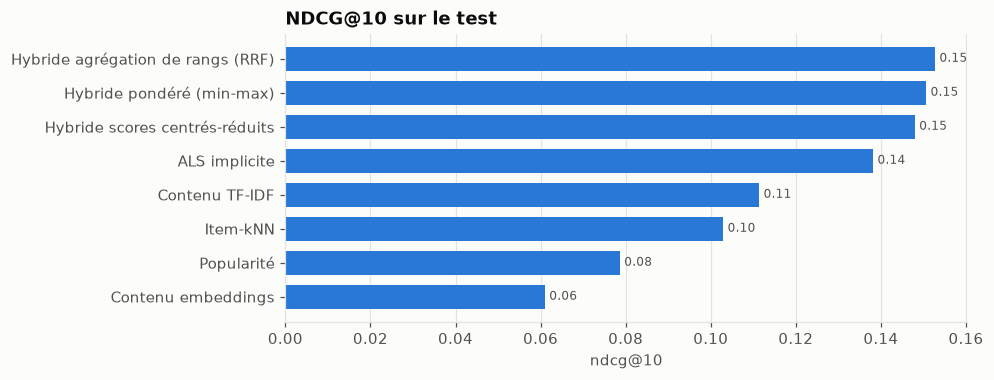

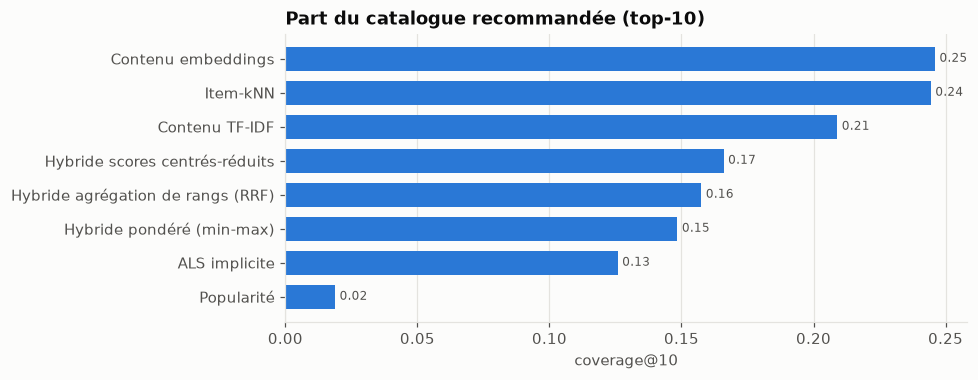

,hyperparamètres retenus,entraînement (s),ms / utilisateur,popularité moyenne du top-10
modèle,,,,
Popularité,relevance_threshold=4.0,0.2241,0.3387,"49,957.1268"
Item-kNN,"k=50, shrinkage=100",92.3335,1.6713,"12,067.9511"
ALS implicite,"factors=64, reg=0.01, alpha=10, iterations=15, relevance_threshold=4.0",111.5858,0.7941,"20,408.3544"
Contenu TF-IDF,"genre_weight=0.2, tag_weight=1.0, title_weight=0.3, aggregation=knn, k=50",6.3147,0.7787,"13,188.5458"
Contenu embeddings,"model=sentence-transformers/all-MiniLM-L6-v2, max_tags=15, aggregation=knn, ...",4.9481,0.5735,"6,227.9196"
Hybride pondéré (min-max),"strategy=weighted, weights=als_implicit 0.50 + item_knn 0.25 + tfidf 0.25",0.0000,1.3242,"19,925.7905"
Hybride scores centrés-réduits,"strategy=zscore, weights=als_implicit 0.50 + item_knn 0.25 + tfidf 0.25",0.0000,1.6376,"18,203.4094"
Hybride agrégation de rangs (RRF),"strategy=rrf, weights=als_implicit 0.50 + item_knn 0.25 + tfidf 0.25",0.0000,4.0017,"19,276.6391"


In [5]:
show(model_report.plot_metric(test, "ndcg@10", "NDCG@10 sur le test"))
show(model_report.plot_metric(test, "coverage@10", "Part du catalogue recommandée (top-10)"))
model_report.cost_table(test).set_index("modèle")

In [6]:
print("Hybride retenu (choisi sur la validation) :", results["best"])

Hybride retenu (choisi sur la validation) : {'model': 'hybrid_rrf', 'params': {'strategy': 'rrf', 'weights': {'als_implicit': 0.5, 'item_knn': 0.25, 'tfidf': 0.25}}, 'validation_ndcg@10': 0.16987954250872556}


## 4. L'hybride en action

On recharge les quatre composants et la recette de l'hybride, puis on reprend l'utilisateur des
notebooks 04 et 05.

In [7]:
components = {
    "als_implicit": ImplicitALS.load(artifacts / collaborative.ARTIFACT_DIR / "als_implicit.pkl"),
    "item_knn": ItemKNN.load(artifacts / collaborative.ARTIFACT_DIR / "item_knn.pkl"),
    "tfidf": ContentBasedRecommender.load(artifacts / content.ARTIFACT_DIR / "tfidf.pkl"),
    "embeddings": ContentBasedRecommender.load(artifacts / content.ARTIFACT_DIR / "embeddings.pkl"),
}
best = HybridRecommender.from_spec(artifacts / hybrid.ARTIFACT_DIR / hybrid.BEST_FILE, components)
matrix = best.matrix
titles = movies.loc[matrix.item_ids, "title"].to_numpy()
genres = movies.loc[matrix.item_ids, "genres"].map(lambda g: ", ".join(g)).to_numpy()
print(best.name, best.params)

hybrid_rrf {'strategy': 'rrf', 'weights': {'als_implicit': 0.5, 'item_knn': 0.25, 'tfidf': 0.25}}


In [8]:
fold = build_folds(load_ratings(config), config)["test"]
history_size = np.diff(matrix.ratings.indptr)
relevant = fold.relevant.groupby("user_idx")["item_idx"].apply(set)
user = [u for u in fold.eval_users if 60 <= history_size[u] <= 150 and len(relevant[u]) >= 8][0]

items, scores = best.recommend(np.array([user]), k=10)
parts = best.contributions(user, items[0])
table = pd.DataFrame({"film": titles[items[0]], "score": scores[0],
                      "aimé ensuite": ["oui" if i in relevant[user] else "" for i in items[0]]})
for name, values in parts.items():
    table[f"part {name}"] = values / scores[0]
print(f"Utilisateur {matrix.user_ids[user]} : {history_size[user]} notes avant la coupure")
table.style.format({c: "{:.0%}" for c in table.columns if c.startswith("part")} | {"score": "{:.3f}"})

Utilisateur 294 : 117 notes avant la coupure


,film,score,aimé ensuite,part als_implicit,part item_knn,part tfidf
0,Apocalypse Now (1979),0.014,,48%,29%,23%
1,2001: A Space Odyssey (1968),0.013,,53%,30%,17%
2,"Silence of the Lambs, The (1991)",0.013,,55%,15%,30%
3,Reservoir Dogs (1992),0.013,,54%,23%,23%
4,Requiem for a Dream (2000),0.013,,50%,24%,27%
5,Psycho (1960),0.012,,57%,31%,12%
6,City of God (Cidade de Deus) (2002),0.010,oui,56%,14%,30%
7,Eternal Sunshine of the Spotless Mind (2004),0.010,,51%,13%,36%
8,Blue Velvet (1986),0.010,,43%,32%,25%
9,Blade Runner (1982),0.010,,56%,34%,9%


Les colonnes `part` donnent la contribution de chaque modèle au score : c'est l'explication que
l'API pourra renvoyer (« recommandé surtout par les goûts d'utilisateurs proches », « surtout
parce que son contenu ressemble à… »).

## 5. Diversité et popularité

Le re-classement MMR part des 50 meilleurs candidats de l'hybride et les réordonne en pénalisant
la ressemblance avec les films déjà placés. La ressemblance est mesurée dans l'espace des
embeddings ; la diversité est aussi rapportée sur les genres, mesure indépendante.

,lambda (MMR),pénalité de popularité,NDCG@10,Recall@10,diversité (embeddings),diversité (genres),couverture@10,popularité moyenne du top-10
0,1.0000,0.0000,0.1527,0.0674,0.5479,0.6257,0.1575,19276.6391
1,0.9000,0.0000,0.1525,0.0671,0.5507,0.6284,0.1579,19290.9901
2,0.7000,0.0000,0.1522,0.0672,0.5586,0.6363,0.1600,19325.2900
3,0.5000,0.0000,0.1510,0.0664,0.5723,0.6479,0.1634,19242.1404
4,0.3000,0.0000,0.1457,0.0638,0.6025,0.6709,0.1691,18792.7815
5,1.0000,0.1000,0.1536,0.0684,0.5478,0.6249,0.1610,19102.2822
6,1.0000,0.2000,0.1543,0.0694,0.5477,0.6237,0.1666,18901.4962
7,1.0000,0.4000,0.1558,0.0716,0.5474,0.6207,0.1782,18394.9943


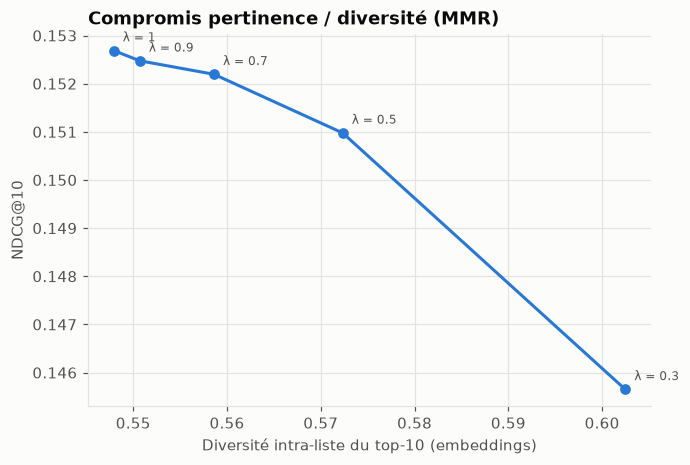

In [9]:
display(hybrid_report.diversity_table(results).style.format(precision=4))
show(hybrid_report.plot_diversity_tradeoff(results))

In [10]:
vectors = np.asarray(components["embeddings"].item_vectors_, dtype=np.float32)


def listing(lam):
    model = DiversifiedRecommender(best, vectors, lam=lam, pool=config.hybrid.diversity_pool)
    top = model.recommend(np.array([user]), k=10)[0]
    ild = metrics.intra_list_diversity(top, vectors, 10)[0]
    return pd.DataFrame({f"λ = {lam:g}  (diversité {ild:.3f})": titles[top[0]],
                         "genres": genres[top[0]]})


display(listing(1.0))
display(listing(0.5))

,λ = 1 (diversité 0.511),genres
0,Apocalypse Now (1979),"Action, Drama, War"
1,2001: A Space Odyssey (1968),"Adventure, Drama, Sci-Fi"
2,"Silence of the Lambs, The (1991)","Crime, Horror, Thriller"
3,Reservoir Dogs (1992),"Crime, Mystery, Thriller"
4,Requiem for a Dream (2000),Drama
5,Psycho (1960),"Crime, Horror"
6,City of God (Cidade de Deus) (2002),"Action, Adventure, Crime, Drama, Thriller"
7,Eternal Sunshine of the Spotless Mind (2004),"Drama, Romance, Sci-Fi"
8,Blue Velvet (1986),"Drama, Mystery, Thriller"
9,Blade Runner (1982),"Action, Sci-Fi, Thriller"


,λ = 0.5 (diversité 0.511),genres
0,Apocalypse Now (1979),"Action, Drama, War"
1,Reservoir Dogs (1992),"Crime, Mystery, Thriller"
2,2001: A Space Odyssey (1968),"Adventure, Drama, Sci-Fi"
3,"Silence of the Lambs, The (1991)","Crime, Horror, Thriller"
4,Requiem for a Dream (2000),Drama
5,Psycho (1960),"Crime, Horror"
6,City of God (Cidade de Deus) (2002),"Action, Adventure, Crime, Drama, Thriller"
7,Blade Runner (1982),"Action, Sci-Fi, Thriller"
8,Blue Velvet (1986),"Drama, Mystery, Thriller"
9,Eternal Sunshine of the Spotless Mind (2004),"Drama, Romance, Sci-Fi"


## 6. Cold start utilisateur

Les utilisateurs apparus après la coupure n'existent pas pour le modèle. On rejoue leur arrivée
en révélant leurs premières notes une à une. Aucun réentraînement : les modèles calculent un
score directement à partir des notes fournies.

,0 note,1 note,3 notes,5 notes,10 notes
modèle,,,,,
Popularité,0.2382,0.2382,0.2382,0.2382,0.2382
ALS implicite,0.0403,0.2171,0.2607,0.2862,0.3263
Item-kNN,0.0403,0.2010,0.2611,0.2930,0.3342
Contenu TF-IDF,0.0403,0.1555,0.1940,0.2177,0.2536
Hybride agrégation de rangs (RRF),0.0483,0.2316,0.2851,0.3195,0.3692
Stratégie cold start (hybride + popularité),0.2382,0.2477,0.2882,0.3187,0.3697


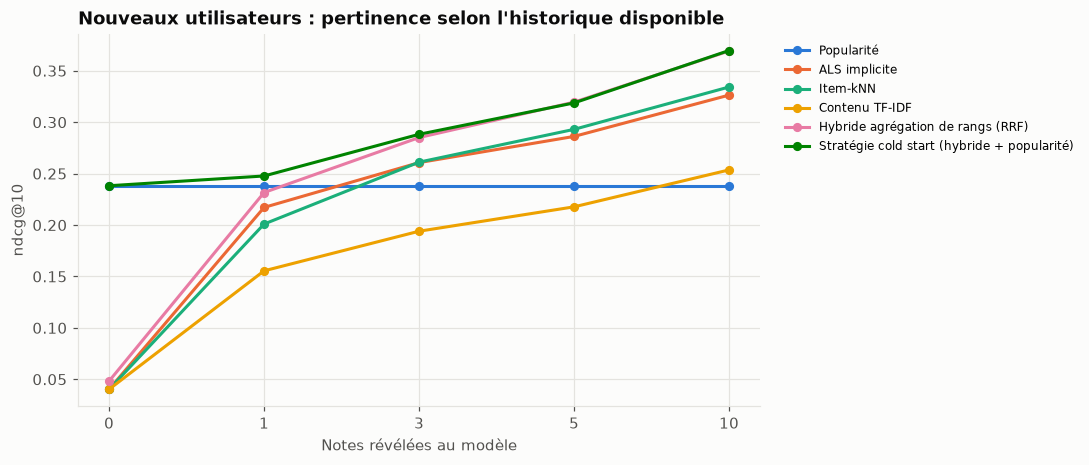

In [11]:
display(hybrid_report.cold_user_table(results).set_index("modèle").style.format("{:.4f}"))
show(hybrid_report.plot_cold_users(results))

### Démonstration : un nouvel utilisateur donne quatre films

L'exemple du cahier des charges : quelqu'un qui aime *Interstellar*, *Inception*, *Matrix* et
*Blade Runner 2049*.

In [12]:
popularity = PopularityRecommender(config.evaluation.relevance_threshold).fit(matrix)
policy = ColdStartRecommender(
    best, popularity, results["cold_users"]["prior_strength"], config.hybrid.rrf_k)
print("Prior retenu sur la validation :", results["cold_users"]["prior_strength"])
counts = np.diff(matrix.ratings.tocsc().indptr)


def newcomer(liked_titles, k=10):
    idx = []
    for part in liked_titles:
        matches = [i for i, t in enumerate(titles) if part.lower() in t.lower()]
        if not matches:
            print(f"(absent du catalogue d'entraînement : {part})")
            continue
        idx.append(max(matches, key=lambda i: counts[i]))
    history = sp.csr_matrix((np.full(len(idx), 5.0, dtype=np.float32), ([0] * len(idx), idx)),
                            shape=(1, matrix.n_items))
    scores = policy.score_history(history)
    scores[0, idx] = -np.inf
    top = np.argsort(-scores[0])[:k]
    print("Films fournis :", [titles[i] for i in idx],
          f"| poids de la popularité : {policy.popularity_weight(np.array([len(idx)]))[0]:.2f}")
    return pd.DataFrame({"film": titles[top], "genres": genres[top], "score": scores[0, top]})


newcomer(["Interstellar", "Inception", "Matrix, The", "Blade Runner 2049"])

Prior retenu sur la validation : 0.5


Films fournis : ['Interstellar (2014)', 'Inception (2010)', 'Matrix, The (1999)', 'Blade Runner 2049 (2017)'] | poids de la popularité : 0.11


,film,genres,score
0,Fight Club (1999),"Action, Crime, Drama, Thriller",0.0157
1,"Dark Knight, The (2008)","Action, Crime, Drama, IMAX",0.0149
2,Star Wars: Episode IV - A New Hope (1977),"Action, Adventure, Sci-Fi",0.0148
3,"Dark Knight Rises, The (2012)","Action, Adventure, Crime, IMAX",0.0143
4,Shutter Island (2010),"Drama, Mystery, Thriller",0.0139
5,"Shawshank Redemption, The (1994)","Crime, Drama",0.0135
6,"Sixth Sense, The (1999)","Drama, Horror, Mystery",0.0135
7,Memento (2000),"Mystery, Thriller",0.0132
8,The Martian (2015),"Adventure, Drama, Sci-Fi",0.0132
9,Avatar (2009),"Action, Adventure, Sci-Fi, IMAX",0.0130


In [13]:
newcomer([])

Films fournis : [] | poids de la popularité : 1.00


,film,genres,score
0,"Shawshank Redemption, The (1994)","Crime, Drama","64,108.0000"
1,Pulp Fiction (1994),"Comedy, Crime, Drama, Thriller","57,449.0000"
2,Forrest Gump (1994),"Comedy, Drama, Romance, War","54,106.0000"
3,"Silence of the Lambs, The (1991)","Crime, Horror, Thriller","53,929.0000"
4,"Matrix, The (1999)","Action, Sci-Fi, Thriller","49,647.0000"
5,Star Wars: Episode IV - A New Hope (1977),"Action, Adventure, Sci-Fi","48,006.0000"
6,Schindler's List (1993),"Drama, War","45,158.0000"
7,"Usual Suspects, The (1995)","Crime, Mystery, Thriller","42,580.0000"
8,Fight Club (1999),"Action, Crime, Drama, Thriller","41,170.0000"
9,Star Wars: Episode V - The Empire Strikes Back (1980),"Action, Adventure, Sci-Fi","40,413.0000"


In [14]:
newcomer(["Notebook, The", "Pride & Prejudice"])

Films fournis : ['Notebook, The (2004)', 'Pride & Prejudice (2005)'] | poids de la popularité : 0.20


,film,genres,score
0,Sense and Sensibility (1995),"Drama, Romance",0.0137
1,Titanic (1997),"Drama, Romance",0.0137
2,Love Actually (2003),"Comedy, Drama, Romance",0.0136
3,Pride and Prejudice (1995),"Drama, Romance",0.0130
4,Bridget Jones's Diary (2001),"Comedy, Drama, Romance",0.0125
5,Atonement (2007),"Drama, Romance, War",0.0124
6,"Devil Wears Prada, The (2006)","Comedy, Drama",0.0121
7,"Holiday, The (2006)","Comedy, Romance",0.0117
8,Emma (1996),"Comedy, Drama, Romance",0.0114
9,"Walk to Remember, A (2002)","Drama, Romance",0.0114


## 7. Cold start film

Un film sans notes suffisantes ne peut pas être recommandé par un modèle collaboratif. Le contenu,
existe dès l'ajout au catalogue. On classe ici uniquement les films sans note d'entraînement.

In [15]:
display(hybrid_report.new_item_table(results).set_index("modèle"))
pd.DataFrame(results["new_items"]["models"]).loc[["n_users", "n_candidates", "mean_relevant_per_user"]]

,recall@10,ndcg@10,recall@20
modèle,,,
Contenu TF-IDF,0.0312,0.0378,0.0355
Hasard,0.0003,0.0005,0.0008
Contenu embeddings,0.0213,0.0244,0.0301


,tfidf,random,embeddings
n_users,"3,837.0000","3,837.0000","3,837.0000"
n_candidates,"26,470.0000","26,470.0000","26,470.0000"
mean_relevant_per_user,9.9781,9.9781,9.9781


## 8. Limites

- Les poids de l'hybride sont choisis parmi sept combinaisons fixées à l'avance, pas optimisés
  en continu : le Sprint 5 apprendra cette combinaison avec un modèle de ranking.
- Le re-classement est décrit sur le test, pas sélectionné : le bon niveau de diversité est une
  décision produit, que seule une expérience en ligne peut trancher.
- Le cold start est simulé sur des utilisateurs réels mais anciens (2018-2019), tous ayant fini
  par noter au moins 20 films : de vrais visiteurs d'un soir se comporteraient autrement.
- Pour un film tout juste ajouté, les tags n'existent pas encore : son contenu se réduit au titre
  et aux genres.